# M203 - Estadística descriptiva e inferencial aplicada

> Módulo II - Data Science
>
> Tema 4: Estadística descriptiva e inferencial aplicada

Contenido:

1. Caracterización de los conjuntos de datos
2. Análisis de datos continuos y distribuciones
3. Análisis de datos discretos y categorías/clases
4. Modelo descriptivo
5. Modelo inferencial

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [2]:
iris = pandas.read_csv("./conjuntos/iris.csv")

iris

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


La flor iris se divide en 3 especies/familias que son Virgínica, Versicolor y la Setosa.

En el conjunto de datos tenemos 150 observaciones anotadas sobre diferentes flores con sus tamaños de largo y ancho de sépalo y pétalo.

![iris1](imagenes/iris1.png)

El conjunto de datos anota en 5 columnas las mediciones, 4 referentes a los tamaños (variables continuas) y una más para la variedad (discreta).

![iris2](imagenes/iris2.jpeg)

El conjunto de datos genera un problema tanto de regresión como de clasificación para problemas de Aprendizaje Supervisado.

![iris3](imagenes/iris3.jpg)

## 1. Caracterización del conjunto de datos

* Definir las características como ejes de datos/información que permitan su análisis individual (continuo o discreto)
* Observar su comportamiento numérico o categórico

In [45]:
c1 = iris["sepal.length"] # Largo del sépalo
c2 = iris["sepal.width"] # Ancho del sépalo
c3 = iris["petal.length"] # Largo del pétalo
c4 = iris["petal.width"] # Ancho del pétalo
c5 = iris["variety"] # Variedad

In [4]:
# Informar la estructura de los datos

c1.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: sepal.length
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [5]:
c2.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: sepal.width
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [6]:
c3.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: petal.length
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [7]:
c4.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: petal.width
Non-Null Count  Dtype  
--------------  -----  
150 non-null    float64
dtypes: float64(1)
memory usage: 1.3 KB


In [8]:
c5.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: variety
Non-Null Count  Dtype
--------------  -----
150 non-null    str  
dtypes: str(1)
memory usage: 1.3 KB


## 2. Análisis de datos continuos y distribuciones

> Supuestos

1. Suponemos que los valor son numéricos
2. Suponemos que los datos se encuentran distribuidos entre un valor mínimo y máximo observados, es decir, no hay valores faltantes
3. Suponemos que su distribución es uniforme o normal (sesgada o insesgada), pero no múlti-pico, es decir, que solo hay a lo más un solo montículo de centralidad en su distribución

In [13]:
# La siguiente serie cumple los supuestos

edades1 = pandas.Series([25, 26, 24, 28, 30, 15, 19, 18, 20, 22, 24, 23, 24, 25, 26, 25, 25, 25])

edades1.sort_values()

5     15
7     18
6     19
8     20
9     22
11    23
2     24
12    24
10    24
15    25
13    25
0     25
16    25
17    25
14    26
1     26
3     28
4     30
dtype: int64

<Axes: ylabel='Density'>

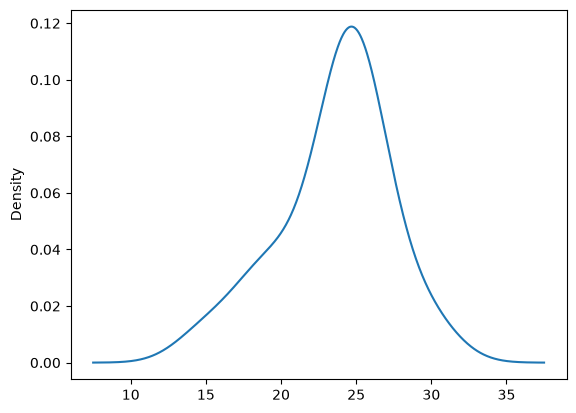

In [14]:
edades1.plot.density()

<Axes: ylabel='Density'>

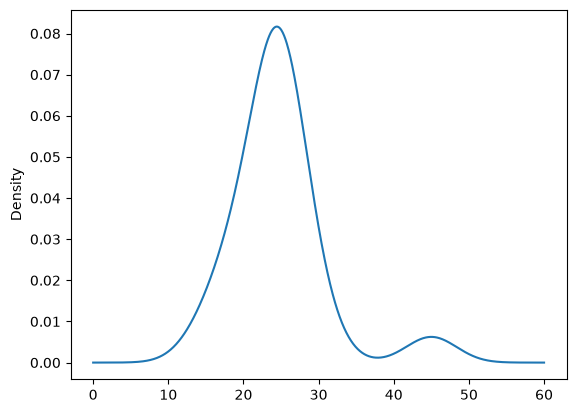

In [16]:
# La siguiente serie no cumple los supuestos

edades2 = pandas.Series([25, 26, 24, 28, 30, 45, 15, 19, 18, 20, 22, 24, 23, 24, 25, 26, 25, 25, 25])

edades2.plot.density()

<Axes: ylabel='Density'>

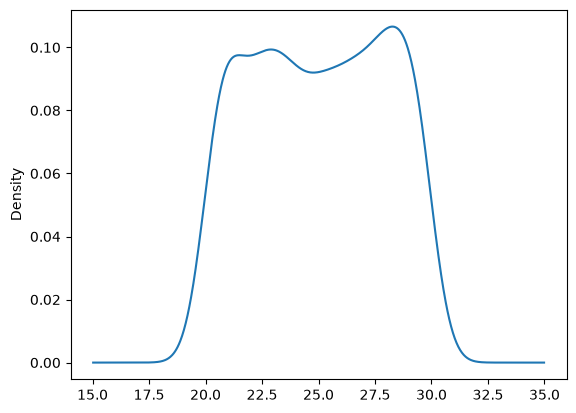

In [23]:
# La siguiente serie cumple los supuestos

edades3 = pandas.Series(
    numpy.random.uniform(20, 30, 1000)
)

edades3.plot.density()

La normalidad de los datos implica supuestos/restricciones todavía más fuertes, en los que se buscan distribuciones aproximadamente normales:

* La distribución de los datos están centrados en un único valor (promedio/media) y se alejan de esa media con probabilidad o densidad cada vez menor, entonces, la probabilidad de encontrar un valor lejano a ese punto/pico centra de la distribución es cada vez menor
* La densidad debe observarse lo más simétrica posible (sino se dirá sesgada hacía izquierda o la derecha)
* El modelo normal aproxima una densidad en forma de campana y se conoce como la distribución gaussiana

$$
f(x) = \frac{1}{\sqrt{\pi \sigma^2}} e^{-\frac{(x - \mu)^2}{\sigma^2}}
$$

Donde $\mu$ es el promedio o media poblacional (puede ser estima en la práctica, si se valida con una prueba de hipótesis el p-valor) y $\sigma$ es la desviación estándar (o $\sigma^2$ es la varianza que también puede ser estimada con los datos y validad con una prueba F).

In [28]:
x = edades1

mu = x.mean()
sigma = x.std()

f = lambda xi: numpy.exp(-(xi - mu) ** 2 / sigma ** 2) / (numpy.pi * sigma ** 2) ** 0.5

y = [f(xi) for xi in x]

pandas.DataFrame({
    "x": x,
    "y": y
}).sort_values("x")

,x,y
5,15,0.000607
7,18,0.014991
6,19,0.032243
8,20,0.059599
9,22,0.129270
11,23,0.151685
2,24,0.152967
12,24,0.152967
10,24,0.152967
15,25,0.132575


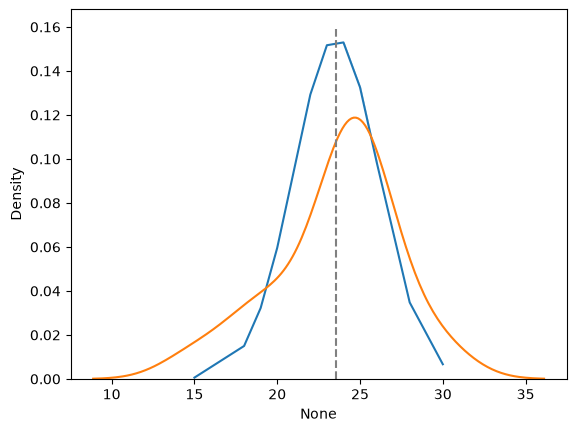

In [33]:
seaborn.lineplot(x=x, y=y) # Normal ideal
seaborn.kdeplot(x=x) # KDE
pyplot.vlines(mu, 0, 0.16, color="gray", linestyle="--")

In [34]:
x.describe()

count    18.000000
mean     23.555556
std       3.633540
min      15.000000
25%      22.250000
50%      24.500000
75%      25.000000
max      30.000000
dtype: float64

### Análisis del largo de sépalo ($c_1$)

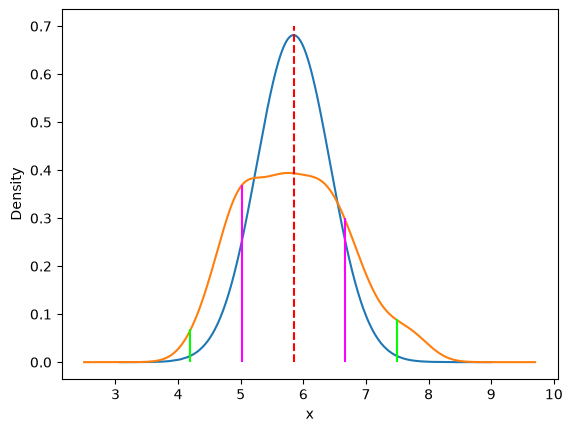

In [66]:
# Una muestra de 1,000 observaciones aleatorias
# similares a C1 - Largo de sépalo (con misma media y desviación estándar)
x_normal = numpy.random.normal(c1.mean(), c1.std(), 1000)
# Curva normal del modelo f(x) = e^-(x - mu) ...
y_normal = numpy.exp(-(x_normal - c1.mean()) ** 2 / c1.var()) / \
            (numpy.pi * c1.var()) ** 0.5
# Curva de muestras aleatorias similares
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
# Curva estimada para nuestros datos reales
c1.plot.density() # KDE
# Dibujamos las anotaciones estadísticas
pyplot.vlines(c1.mean(), 0, 0.7, color="red", linestyle="--")
pyplot.vlines(c1.mean() + c1.std(), 0, 0.3, color="magenta", linestyle="-")
pyplot.vlines(c1.mean() - c1.std(), 0, 0.37, color="magenta", linestyle="-")
pyplot.vlines(c1.mean() + 2 * c1.std(), 0, 0.09, color="lime", linestyle="-")
pyplot.vlines(c1.mean() - 2 * c1.std(), 0, 0.07, color="lime", linestyle="-")

Puntos de observación:

1. La curva estima está menos densa en el centro (tiene densidad más baja), es decir, los datos no son tan centrales a la media
2. Tenemos colas pesadas que indican posibles sesgos hacia los extremos de izquierda y derecha, es decir, hay posibles diferencias entre grupos no identificados

In [48]:
# Estasdísticos para C1 - Largo del sépalo

c1.describe()

count    150.000000
mean       5.843333
std        0.828066
min        4.300000
25%        5.100000
50%        5.800000
75%        6.400000
max        7.900000
Name: sepal.length, dtype: float64

En una distribución normal, podemos estimar cuántos datos serán cubiertos en un intervalor que se aleja de la media con razón de la desviación estándar:

$$
I_{covertura}: (\mu - i \sigma, \mu + i \sigma)
$$

![normal1](imagenes/normal1.png)

In [71]:
# Intervalos de covertura para C1 - Largo del sépalo

pandas.DataFrame({
    "68%": [c1.mean() - 1 * c1.std(), c1.mean() + 1 * c1.std()],
    "95%": [c1.mean() - 2 * c1.std(), c1.mean() + 2 * c1.std()],
    "99.7%": [c1.mean() - 3 * c1.std(), c1.mean() + 3 * c1.std()],
}, index=["-i * sigma", "+i * sigma"]).T

,-i * sigma,+i * sigma
68%,5.015267,6.671399
95%,4.187201,7.499466
99.7%,3.359135,8.327532


In [79]:
print(f"68% | {100 * c1[(c1 >= 5.0152) & (c1 <= 6.6714)].count() / c1.count():.0f}%")
print(f"95% | {100 * c1[(c1 >= 4.1872) & (c1 <= 7.5)].count() / c1.count():.0f}%")
print(f"99.7% | {100 * c1[(c1 >= 3.3591) & (c1 <= 8.3275)].count() / c1.count():.0f}%")

68% | 60%
95% | 96%
99.7% | 100%


### Análisis del ancho de sépalo ($c_2$)

count    150.000000
mean       3.057333
std        0.435866
min        2.000000
25%        2.800000
50%        3.000000
75%        3.300000
max        4.400000
Name: sepal.width, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      2.621467    3.493200
95%      2.185601    3.929066
99.7%    1.749734    4.364932
------------------------------------------------------------
68% | 67%
95% | 97%
99.7% | 99%
------------------------------------------------------------


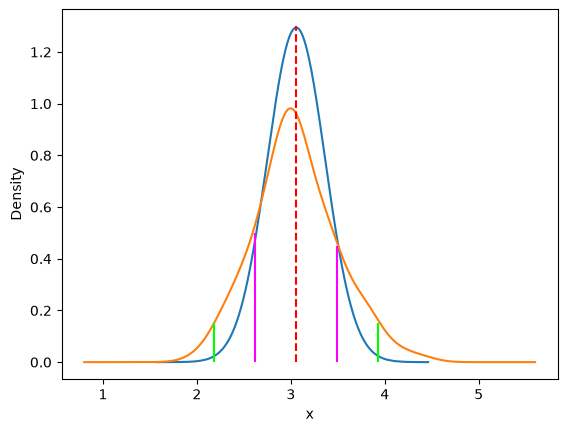

In [98]:
print(c2.describe())
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c2.mean() - 1 * c2.std(), c2.mean() + 1 * c2.std()],
    "95%": [c2.mean() - 2 * c2.std(), c2.mean() + 2 * c2.std()],
    "99.7%": [c2.mean() - 3 * c2.std(), c2.mean() + 3 * c2.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c2[(c2 >= intervalos.iloc[0, 0]) & (c2 <= intervalos.iloc[0, 1])].count() / c2.count():.0f}%")
print(f"95% | {100 * c2[(c2 >= intervalos.iloc[1, 0]) & (c2 <= intervalos.iloc[1, 1])].count() / c2.count():.0f}%")
print(f"99.7% | {100 * c2[(c2 >= intervalos.iloc[2, 0]) & (c2 <= intervalos.iloc[2, 1])].count() / c2.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c2.mean(), c2.std(), 1000)
y_normal = numpy.exp(-(x_normal - c2.mean()) ** 2 / c2.var()) / \
            (numpy.pi * c2.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c2.plot.density() # KDE
pyplot.vlines(c2.mean(), 0, 1.3, color="red", linestyle="--")
pyplot.vlines(c2.mean() - c2.std(), 0, 0.5, color="magenta", linestyle="-")
pyplot.vlines(c2.mean() + c2.std(), 0, 0.45, color="magenta", linestyle="-")
pyplot.vlines(c2.mean() - 2 * c2.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.vlines(c2.mean() + 2 * c2.std(), 0, 0.15, color="lime", linestyle="-")
pyplot.show()

### Análisis del largo de pétalo ($c_3$)

count    150.000000
mean       3.758000
std        1.765298
min        1.000000
25%        1.600000
50%        4.350000
75%        5.100000
max        6.900000
Name: petal.length, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      1.992702    5.523298
95%      0.227404    7.288596
99.7%   -1.537895    9.053895
------------------------------------------------------------
68% | 50%
95% | 100%
99.7% | 100%
------------------------------------------------------------


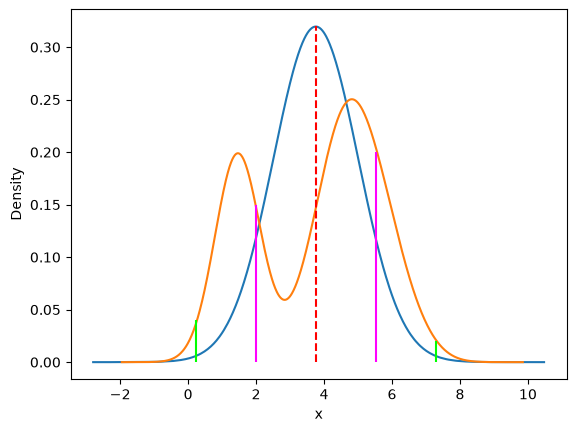

In [109]:
print(c3.describe())
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c3.mean() - 1 * c3.std(), c3.mean() + 1 * c3.std()],
    "95%": [c3.mean() - 2 * c3.std(), c3.mean() + 2 * c3.std()],
    "99.7%": [c3.mean() - 3 * c3.std(), c3.mean() + 3 * c3.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c3[(c3 >= intervalos.iloc[0, 0]) & (c3 <= intervalos.iloc[0, 1])].count() / c3.count():.0f}%")
print(f"95% | {100 * c3[(c3 >= intervalos.iloc[1, 0]) & (c3 <= intervalos.iloc[1, 1])].count() / c3.count():.0f}%")
print(f"99.7% | {100 * c3[(c3 >= intervalos.iloc[2, 0]) & (c3 <= intervalos.iloc[2, 1])].count() / c3.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c3.mean(), c3.std(), 1000)
y_normal = numpy.exp(-(x_normal - c3.mean()) ** 2 / c3.var()) / \
            (numpy.pi * c3.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c3.plot.density() # KDE
pyplot.vlines(c3.mean(), 0, 0.32, color="red", linestyle="--")
pyplot.vlines(c3.mean() - c3.std(), 0, 0.15, color="magenta", linestyle="-")
pyplot.vlines(c3.mean() + c3.std(), 0, 0.2, color="magenta", linestyle="-")
pyplot.vlines(c3.mean() - 2 * c3.std(), 0, 0.04, color="lime", linestyle="-")
pyplot.vlines(c3.mean() + 2 * c3.std(), 0, 0.02, color="lime", linestyle="-")
pyplot.show()

### Análisis del ancho de pétalo ($c_4$)

count    150.000000
mean       1.199333
std        0.762238
min        0.100000
25%        0.300000
50%        1.300000
75%        1.800000
max        2.500000
Name: petal.width, dtype: float64
------------------------------------------------------------
       -i * sigma  +i * sigma
68%      0.437096    1.961571
95%     -0.325142    2.723809
99.7%   -1.087380    3.486046
------------------------------------------------------------
68% | 49%
95% | 100%
99.7% | 100%
------------------------------------------------------------


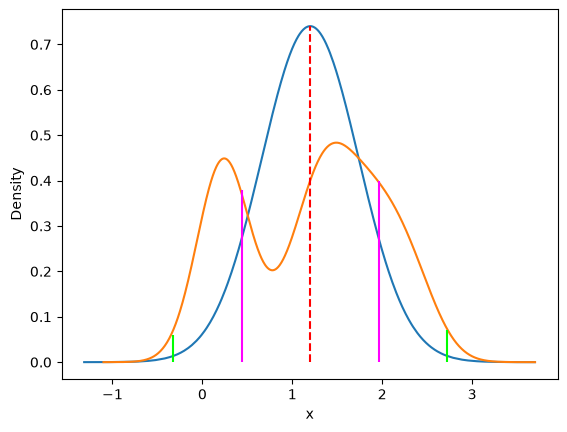

In [119]:
print(c4.describe()) # RECESO DE 11:00 a 11:20
print("-" * 60)

intervalos = pandas.DataFrame({
    "68%": [c4.mean() - 1 * c4.std(), c4.mean() + 1 * c4.std()],
    "95%": [c4.mean() - 2 * c4.std(), c4.mean() + 2 * c4.std()],
    "99.7%": [c4.mean() - 3 * c4.std(), c4.mean() + 3 * c4.std()],
}, index=["-i * sigma", "+i * sigma"]).T

print(intervalos)
print("-" * 60)

print(f"68% | {100 * c4[(c4 >= intervalos.iloc[0, 0]) & (c4 <= intervalos.iloc[0, 1])].count() / c4.count():.0f}%")
print(f"95% | {100 * c4[(c4 >= intervalos.iloc[1, 0]) & (c4 <= intervalos.iloc[1, 1])].count() / c4.count():.0f}%")
print(f"99.7% | {100 * c4[(c4 >= intervalos.iloc[2, 0]) & (c4 <= intervalos.iloc[2, 1])].count() / c4.count():.0f}%")
print("-" * 60)

x_normal = numpy.random.normal(c4.mean(), c4.std(), 1000)
y_normal = numpy.exp(-(x_normal - c4.mean()) ** 2 / c4.var()) / \
            (numpy.pi * c4.var()) ** 0.5
curva = pandas.DataFrame({"x": x_normal, "y": y_normal}).sort_values("x")
seaborn.lineplot(x=curva["x"], y=curva["y"]) # NORMAL
c4.plot.density() # KDE
pyplot.vlines(c4.mean(), 0, 0.74, color="red", linestyle="--")
pyplot.vlines(c4.mean() - c4.std(), 0, 0.38, color="magenta", linestyle="-")
pyplot.vlines(c4.mean() + c4.std(), 0, 0.4, color="magenta", linestyle="-")
pyplot.vlines(c4.mean() - 2 * c4.std(), 0, 0.06, color="lime", linestyle="-")
pyplot.vlines(c4.mean() + 2 * c4.std(), 0, 0.07, color="lime", linestyle="-")
pyplot.show()